# Step 5.1: Cosmic-Ray Spikes

Inference only. The Step 4 checkpoints are reloaded and never modified, and Step 5.0 has confirmed that the reload reproduces the clean baseline.

**In the paper.** The spike table (density and amplitude sweeps, Sections 5.1.5 to 5.1.7), Fig. 2a (`step51_degradation_density.csv`, `step51_degradation_amplitude.csv`), Fig. 2b (damage by landing position, Section 5.1.10, `step51_susceptibility.csv`) and Fig. 2c (clean rank against attacked rank by regime, Section 5.1.7). The spikes are idealised: they are injected into the resampled, normalised spectrum rather than into the raw exposures.

**The perturbation.** At $k$ randomly chosen pixels of each spectrum, the flux is *replaced* by a fixed value $C$. Replacement rather than addition is deliberate: an additive spike falling into the floor of a deep absorption line would be partly cancelled by that line, making the effective strength depend on where it landed. Replacement gives a uniform amplitude everywhere.

$$
f_{\text{attacked}}(\lambda_i) = C, \qquad i \in \mathcal{K},\ |\mathcal{K}| = k
$$

**Two sweeps, because density and amplitude are separate variables.**

*Sweep A — density.* $k \in \{1, 2, 5, 10, 20, 50\}$ at fixed $C = 5$. At $k = 50$ the attack touches 1.2% of the input.

*Sweep B — amplitude.* $C \in \{1, 2, 3, 5, 10, 20\}$ at fixed $k = 5$, with the spike **positions held identical across all amplitudes**, so that the only thing varying is how far the corrupted pixel sits outside the normal flux range. The level $C = 1$ is the control that carries the argument: it places the corrupted pixels exactly at the continuum level, destroying the same five pixels of information while introducing no outlier at all. If a model is damaged at $C = 5$ but not at $C = 1$, the damage comes from outlier magnitude rather than from information loss.

**Why this attack reaches the model bodies.** Step 4 chose max pooling over average pooling in the shared stem for exactly this reason. A single high-amplitude pixel survives two max-pool layers and two stride-2 convolutions, so it reaches both bodies intact; with average pooling it would be attenuated 32-fold before either branch could respond, and the comparison would measure the stem rather than the two bodies.

## 5.1.1 Configuration

`N_REPEATS` sets how many independent draws of spike positions are evaluated per level. Two draws were used for the density sweep in order to check that draw-to-draw scatter is negligible against seed-to-seed scatter; that check having passed, the amplitude sweep uses a single draw.

Every model and seed sees the **identical** corrupted tensor at each level: the tensor is built once and pushed through all ten networks before the next one is generated. Otherwise an architecture difference would be confounded with the sampling variance of the noise itself.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'
STEP51_DIR  = os.path.join(RESULTS_DIR, 'step51')

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

BATCH_SIZE = 256

# ---- attack ------------------------------------------------------------------
ATTACK      = 'cosmic_ray'
ATTACK_SEED = 51          # RNG stream for the perturbation, independent of model seeds

K_LEVELS    = [1, 2, 5, 10, 20, 50]     # sweep A: density, at C = C_REF
C_REF       = 5.0
N_REPEATS_K = 2

C_LEVELS    = [1.0, 2.0, 3.0, 5.0, 10.0, 20.0]   # sweep B: amplitude, at k = K_REF
K_REF       = 5
N_REPEATS_C = 1

CATASTROPHIC_K = 300.0    # same convention as Step 5.0

# metrics carried through from Step 5.0; the clean value of each is subtracted
# from its attacked counterpart within the same model and seed
METRIC_COLS = ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA AND THE STEP 5.0 BASELINE
# ==========================================
import common
device = common.get_device()

os.makedirs(STEP51_DIR, exist_ok=True)

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID_N      = prep['grid']['seq_length']
REG_EDGES   = meta50['regime_edges_K']

assert meta50['gate_passed'], 'Step 5.0 integrity gate did not pass'
assert meta50['eval_batch_size'] == BATCH_SIZE, 'batch size differs from Step 5.0'

clean_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))


print(f'Device   : {device}')
print(f'Sweep A  : k in {K_LEVELS} at C = {C_REF}, {N_REPEATS_K} draws')
print(f'Sweep B  : C in {C_LEVELS} at k = {K_REF}, {N_REPEATS_C} draw')

Device   : cpu
Sweep A  : k in [1, 2, 5, 10, 20, 50] at C = 5.0, 2 draws
Sweep B  : C in [1.0, 2.0, 3.0, 5.0, 10.0, 20.0] at k = 5, 1 draw


## 5.1.2 Architectures

The two models are defined once, in `models.py`, and loaded through `common.py` exactly as in Step 5.0. The parity check halts the notebook if a definition has drifted from the one the checkpoints were written against.

In [2]:
from models import SharedStem, check_parameter_parity
import common

check_parameter_parity()


def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)


## 5.1.3 Test partition

Loaded exactly as in Step 5.0 and Step 4a. The clean tensor stays intact on the device and each corrupted version is written into a separate buffer, so no perturbation can leak into the next through an in-place edit.

The flux percentiles printed below set the scale for the amplitude sweep: they say how far outside the normal range each value of $C$ actually sits.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_clean = torch.from_numpy(X_test).to(device)

regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]
regime_mask = {str(c): np.asarray(regime == c) for c in regime.categories}

assert not np.isnan(X_test).any(), 'NaN in the test tensor'

print(f'test spectra : {N_TEST:,}')
print(f'flux         : p50 {np.percentile(X_test, 50):.3f}   '
      f'p99 {np.percentile(X_test, 99):.3f}   '
      f'p99.99 {np.percentile(X_test, 99.99):.2f}   max {X_test.max():.1f}')
print()
print('where each amplitude sits in the clean flux distribution:')
for C in C_LEVELS:
    frac = float(np.mean(X_test > C))
    print(f'  C = {C:5.1f}   {100 * frac:8.5f}% of clean pixels exceed it')

test spectra : 18,898
flux         : p50 1.000   p99 2.091   p99.99 6.51   max 79.1

where each amplitude sits in the clean flux distribution:
  C =   1.0   49.99251% of clean pixels exceed it
  C =   2.0    1.21421% of clean pixels exceed it
  C =   3.0    0.17825% of clean pixels exceed it
  C =   5.0    0.02488% of clean pixels exceed it
  C =  10.0    0.00183% of clean pixels exceed it
  C =  20.0    0.00075% of clean pixels exceed it


## 5.1.4 The perturbation

Positions are drawn independently for every spectrum, since a cosmic-ray event on one exposure has nothing to do with another. They are drawn **without replacement** within a spectrum, so a nominal $k$ always means exactly $k$ distinct corrupted pixels: at $k = 50$, naive sampling with replacement would leave about a quarter of the spectra with fewer than 50 by collision alone.

The stream is seeded from `(ATTACK_SEED, k, repeat)` and depends on neither the model, the seed, nor the batch order. Because the amplitude sweep uses `k = 5` and `repeat = 0`, it reproduces exactly the positions of the density sweep at $k = 5$ — so the two sweeps intersect at $(k=5,\ C=5)$, and that shared point doubles as a reproducibility check.

In [4]:
def spike_positions(n_rows, k, rng, chunk=2048):
    """k distinct pixel indices per row, drawn uniformly over the full grid."""
    out = np.empty((n_rows, k), dtype=np.int16)
    for i in range(0, n_rows, chunk):
        j = min(i + chunk, n_rows)
        r = rng.random((j - i, GRID_N), dtype=np.float32)
        out[i:j] = np.argpartition(r, k, axis=1)[:, :k].astype(np.int16)
    return out


def apply_spikes(x_clean, pos, value):
    """Return a corrupted copy; x_clean is left untouched."""
    x = x_clean.clone()
    rows = torch.arange(x.shape[0], device=x.device).unsqueeze(1)
    cols = torch.from_numpy(pos.astype(np.int64)).to(x.device)
    x[rows, 0, cols] = value
    return x


def run_level(pos, value, n_test):
    """Evaluate all ten networks on one corrupted tensor."""
    X_att = apply_spikes(X_clean, pos, value)
    out = np.empty((len(SEEDS), len(MODELS), n_test), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            out[si, mi] = predict(model, X_att).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    del X_att
    return out


def path_k(k):
    return os.path.join(STEP51_DIR, f'preds_k{k:03d}.npz')

def path_c(C):
    return os.path.join(STEP51_DIR, f'preds_k{K_REF:03d}_C{C:g}.npz')

## 5.1.5 Sweep A — spike density

Results are written per level, so an interrupted run resumes at the next level rather than starting over. Per-spectrum predictions and the spike positions are both stored; they cost a few megabytes and make the position analysis of Section 5.1.10 possible without re-running the attack.

In [5]:
_m = load_model(MODELS[0], SEEDS[0])
_t0 = time.time(); predict(_m, X_clean); _t = time.time() - _t0
del _m
if device.type == 'cuda':
    torch.cuda.empty_cache()

todo = (sum(N_REPEATS_K for k in K_LEVELS if not os.path.exists(path_k(k)))
        + sum(N_REPEATS_C for C in C_LEVELS if not os.path.exists(path_c(C))))
print(f'one forward pass  : {_t:.1f} s')
print(f'tensors to run    : {todo}  ({todo * len(SEEDS) * len(MODELS)} forward passes)')
print(f'projected total   : {_t * todo * len(SEEDS) * len(MODELS) * 1.4 / 60:.0f} min')

one forward pass  : 16.5 s
tensors to run    : 18  (180 forward passes)
projected total   : 69 min


In [6]:
for k in K_LEVELS:
    if os.path.exists(path_k(k)):
        print(f'[skip] k = {k:3d}')
        continue
    t0 = time.time()
    preds = np.empty((N_REPEATS_K, len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    positions = np.empty((N_REPEATS_K, N_TEST, k), dtype=np.int16)

    for rep in range(N_REPEATS_K):
        rng = np.random.default_rng([ATTACK_SEED, k, rep])
        positions[rep] = spike_positions(N_TEST, k, rng)
        preds[rep] = run_level(positions[rep], C_REF, N_TEST)

    np.savez_compressed(path_k(k), preds=preds, positions=positions,
                        seeds=np.array(SEEDS), models=np.array(MODELS),
                        k=k, spike_value=C_REF, attack_seed=ATTACK_SEED)
    rmse = np.sqrt(((preds - y_true_k[None, None, None, :]) ** 2).mean(axis=-1))
    print(f'k = {k:3d}   ' + '   '.join(
        f'{m} {rmse[:, :, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')

k =   1   Conv-Pool   96.29 K   Conv-Attn   87.33 K   (346s)
k =   2   Conv-Pool  115.13 K   Conv-Attn   92.97 K   (351s)
k =   5   Conv-Pool  177.40 K   Conv-Attn  108.85 K   (360s)
k =  10   Conv-Pool  294.38 K   Conv-Attn  141.21 K   (347s)
k =  20   Conv-Pool  514.34 K   Conv-Attn  225.42 K   (364s)
k =  50   Conv-Pool  883.30 K   Conv-Attn  581.02 K   (377s)


## 5.1.6 Sweep B — spike amplitude

Five pixels per spectrum throughout, at the same positions throughout. Only the value written into them changes.

This sweep exists to separate two explanations of Sweep A that its results cannot distinguish. Under the first, the damage comes from the *information destroyed* at the corrupted pixels; under the second, it comes from the *magnitude of the outlier* those pixels introduce, which propagates through the network as an anomalous activation. The $C = 1$ level separates them cleanly: it destroys exactly the same five pixels while placing them at the continuum level, where they are not outliers at all.

The distinction matters for what may be claimed. The two bodies differ in more than attention versus convolution: the Pre-LN Transformer normalises every token individually, whereas the residual convolutional blocks use batch normalisation, which at inference applies fixed running statistics. The amplitude sweep can show that the architectural gap is driven by outlier magnitude rather than by information loss. It does not identify which component of the body bounds the outlier, and no such attribution is made from it.

In [7]:
for C in C_LEVELS:
    if os.path.exists(path_c(C)):
        print(f'[skip] C = {C:5.1f}')
        continue
    t0 = time.time()
    preds = np.empty((N_REPEATS_C, len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    positions = np.empty((N_REPEATS_C, N_TEST, K_REF), dtype=np.int16)

    for rep in range(N_REPEATS_C):
        rng = np.random.default_rng([ATTACK_SEED, K_REF, rep])   # same as sweep A
        positions[rep] = spike_positions(N_TEST, K_REF, rng)
        preds[rep] = run_level(positions[rep], C, N_TEST)

    np.savez_compressed(path_c(C), preds=preds, positions=positions,
                        seeds=np.array(SEEDS), models=np.array(MODELS),
                        k=K_REF, spike_value=C, attack_seed=ATTACK_SEED)
    rmse = np.sqrt(((preds - y_true_k[None, None, None, :]) ** 2).mean(axis=-1))
    print(f'C = {C:5.1f}   ' + '   '.join(
        f'{m} {rmse[:, :, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')

C =   1.0   Conv-Pool   85.56 K   Conv-Attn   85.80 K   (188s)
C =   2.0   Conv-Pool   98.55 K   Conv-Attn   94.87 K   (188s)
C =   3.0   Conv-Pool  122.65 K   Conv-Attn  101.40 K   (188s)
C =   5.0   Conv-Pool  176.35 K   Conv-Attn  108.69 K   (190s)
C =  10.0   Conv-Pool  271.43 K   Conv-Attn  130.89 K   (189s)
C =  20.0   Conv-Pool  397.06 K   Conv-Attn  209.03 K   (188s)


In [8]:
# --- the two sweeps intersect at (k = 5, C = 5): they must agree exactly --------
a = np.load(path_k(K_REF))
b = np.load(path_c(C_REF))
pos_match = bool((a['positions'][0] == b['positions'][0]).all())
pred_diff = float(np.abs(a['preds'][0] - b['preds'][0]).max())
print(f'shared point (k={K_REF}, C={C_REF:g})')
print(f'  identical spike positions : {pos_match}')
print(f'  max |prediction diff|     : {pred_diff:.6f} K')
if not pos_match or pred_diff > 0.05:
    print('  WARNING: the sweeps disagree at their shared point; check the RNG stream.')
del a, b

shared point (k=5, C=5)
  identical spike positions : True
  max |prediction diff|     : 0.000000 K


## 5.1.7 Degradation

Every quantity is a difference against the Step 5.0 clean value, taken **within the same model and seed**. That pairing removes the clean architecture gap and the per-seed bias offset, whose seed-to-seed scatter of roughly 3 K would otherwise swamp anything measured here.

Draws are averaged before seeds, so the reported standard deviation is seed-to-seed scatter.

In [9]:
def degradation_table(paths, level_name):
    rows = []
    for level, p in paths:
        z = np.load(p)
        preds = z['preds']
        for rep in range(preds.shape[0]):
            for si, seed in enumerate(SEEDS):
                for mi, m in enumerate(MODELS):
                    pr = preds[rep, si, mi].astype(np.float64)
                    rows.append({level_name: level, 'repeat': rep, 'model': m,
                                 'seed': seed, 'regime': 'all',
                                 **metrics(pr, y_true_k)})
                    for lab, sel in regime_mask.items():
                        rows.append({level_name: level, 'repeat': rep, 'model': m,
                                     'seed': seed, 'regime': lab,
                                     **metrics(pr[sel], y_true_k[sel])})
    raw = pd.DataFrame(rows)
    att = (raw.groupby([level_name, 'model', 'seed', 'regime'])[METRIC_COLS]
           .mean().reset_index())
    deg = att.merge(clean_metrics[['model', 'seed', 'regime'] + METRIC_COLS],
                    on=['model', 'seed', 'regime'], suffixes=('', '_clean'))
    for c in METRIC_COLS:
        deg['d_' + c] = deg[c] - deg[c + '_clean']
    return raw, deg


raw_k, deg_k = degradation_table([(k, path_k(k)) for k in K_LEVELS], 'k')
raw_c, deg_c = degradation_table([(C, path_c(C)) for C in C_LEVELS], 'C')

deg_k.to_csv(os.path.join(RESULTS_DIR, 'step51_degradation_density.csv'), index=False)
deg_c.to_csv(os.path.join(RESULTS_DIR, 'step51_degradation_amplitude.csv'), index=False)

# --- draw variance against seed variance, sweep A ------------------------------
draw_sd = (raw_k.query("regime == 'all'")
           .groupby(['k', 'model', 'seed'])['rmse_K'].std()
           .groupby(['k', 'model']).mean())
seed_sd = (deg_k.query("regime == 'all'")
           .groupby(['k', 'model'])['rmse_K'].std())
print('RMSE scatter (K): draw-to-draw vs seed-to-seed')
display(pd.DataFrame({'draw_sd': draw_sd, 'seed_sd': seed_sd}).round(2))

RMSE scatter (K): draw-to-draw vs seed-to-seed


draw_sd  seed_sd
k  model                      
1  Conv-Attn     0.42     1.10
   Conv-Pool     0.27     3.64
2  Conv-Attn     0.35     1.79
   Conv-Pool     0.52     7.32
5  Conv-Attn     0.67     4.05
   Conv-Pool     1.64    17.83
10 Conv-Attn     2.38     6.72
   Conv-Pool     0.73    37.27
20 Conv-Attn     0.83    12.72
   Conv-Pool     1.44    58.08
50 Conv-Attn     0.90    89.06
   Conv-Pool     0.74    38.90

In [10]:
ov_k = deg_k.query("regime == 'all'")

piv = ov_k.pivot_table(index='k', columns='model',
                       values=['d_rmse_K', 'd_p99_abs_K'], aggfunc=['mean', 'std'])
piv.columns = [f'{v.replace("d_", "").replace("_K", "")}_{mod}_{ag}'
               for ag, v, mod in piv.columns]
piv['rmse_gap'] = piv['rmse_Conv-Attn_mean'] - piv['rmse_Conv-Pool_mean']
piv['rmse_ratio'] = piv['rmse_Conv-Pool_mean'] / piv['rmse_Conv-Attn_mean']
print('Sweep A — degradation by spike density (K):')
display(piv.round(2))

print('\nSeed-to-seed scatter of the degradation is the relevant yardstick here, not '
      'the 1.5 K clean-data threshold of Step 5.0: under attack it grows to tens of K.')

Sweep A — degradation by spike density (K):


,p99_abs_Conv-Attn_mean,p99_abs_Conv-Pool_mean,rmse_Conv-Attn_mean,rmse_Conv-Pool_mean,p99_abs_Conv-Attn_std,p99_abs_Conv-Pool_std,rmse_Conv-Attn_std,rmse_Conv-Pool_std,rmse_gap,rmse_ratio
k,,,,,,,,,,
1,17.61,45.33,5.61,15.22,2.59,6.57,0.86,3.21,-9.61,2.71
2,35.86,107.37,11.25,34.06,4.56,16.93,1.67,6.91,-22.81,3.03
5,87.58,306.18,27.13,96.33,11.83,46.26,3.97,17.46,-69.20,3.55
10,201.56,677.03,59.49,213.30,38.99,102.22,6.84,36.93,-153.82,3.59
20,510.49,1262.97,143.69,433.27,85.13,134.64,13.08,57.70,-289.58,3.02
50,1339.55,2015.58,499.30,802.22,132.76,109.37,89.09,38.47,-302.92,1.61



Seed-to-seed scatter of the degradation is the relevant yardstick here, not the 1.5 K clean-data threshold of Step 5.0: under attack it grows to tens of K.


In [11]:
tests = []
for k in K_LEVELS:
    a = ov_k[(ov_k.k == k) & (ov_k.model == 'Conv-Pool')].sort_values('seed')['d_rmse_K'].values
    b = ov_k[(ov_k.k == k) & (ov_k.model == 'Conv-Attn')].sort_values('seed')['d_rmse_K'].values
    d = b - a
    t, p = stats.ttest_rel(b, a)
    tests.append({'k': k, 'gap_K': float(d.mean()), 'sd_of_diff': float(d.std(ddof=1)),
                  'gap_over_sd': float(d.mean() / d.std(ddof=1)),
                  't': float(t), 'p_paired_t': float(p),
                  'p_wilcoxon': float(stats.wilcoxon(b, a).pvalue)})
tests = pd.DataFrame(tests)
display(tests.round(4))
print('k = 5 is the reference level shared with the amplitude sweep; the levels '
      'together form a degradation curve and carry no multiplicity-corrected claim. '
      'With five seeds the Wilcoxon test cannot fall below p = 0.0625 regardless of '
      'effect size, so the paired t and the gap-to-scatter ratio are the informative '
      'columns.')

,k,gap_K,sd_of_diff,gap_over_sd,t,p_paired_t,p_wilcoxon
0,1,-9.6123,2.8552,-3.3666,-7.5280,0.0017,0.0625
1,2,-22.8128,6.5098,-3.5044,-7.8361,0.0014,0.0625
2,5,-69.2046,17.8661,-3.8735,-8.6615,0.0010,0.0625
3,10,-153.8166,34.7490,-4.4265,-9.8980,0.0006,0.0625
4,20,-289.5793,48.5888,-5.9598,-13.3265,0.0002,0.0625
5,50,-302.9236,123.8217,-2.4465,-5.4704,0.0054,0.0625


k = 5 is the reference level shared with the amplitude sweep; the levels together form a degradation curve and carry no multiplicity-corrected claim. With five seeds the Wilcoxon test cannot fall below p = 0.0625 regardless of effect size, so the paired t and the gap-to-scatter ratio are the informative columns.


In [12]:
ov_c = deg_c.query("regime == 'all'")

pic = ov_c.pivot_table(index='C', columns='model', values='d_rmse_K',
                       aggfunc=['mean', 'std'])
pic.columns = [f'{mod}_{ag}' for ag, mod in pic.columns]
pic['ratio_Pool_over_Attn'] = pic['Conv-Pool_mean'] / pic['Conv-Attn_mean']
print(f'Sweep B — degradation by spike amplitude at k = {K_REF} (K):')
display(pic.round(2))

print('\nReading the control level:')
for m in MODELS:
    d1 = float(ov_c[(ov_c.C == 1.0) & (ov_c.model == m)]['d_rmse_K'].mean())
    d5 = float(ov_c[(ov_c.C == C_REF) & (ov_c.model == m)]['d_rmse_K'].mean())
    tail = f'{d5 / d1:6.1f}x' if d1 > 0.05 else 'ratio undefined (C=1 damage ~ 0)'
    print(f'  {m:10s} C=1 (continuum, no outlier) {d1:8.2f} K   '
          f'C=5 {d5:8.2f} K   attributable to outlier magnitude {d5 - d1:8.2f} K   {tail}')
print('\nDamage at C = 1 is the most that information loss alone can account for, since '
      'those five pixels are destroyed just as thoroughly but sit at the continuum level '
      'and are not outliers. Everything above it is attributable to outlier magnitude.')

Sweep B — degradation by spike amplitude at k = 5 (K):


,Conv-Attn_mean,Conv-Pool_mean,Conv-Attn_std,Conv-Pool_std,ratio_Pool_over_Attn
C,,,,,
1.0,4.07,4.49,0.76,0.40,1.10
2.0,13.15,17.47,1.47,2.17,1.33
3.0,19.68,41.58,2.50,7.13,2.11
5.0,26.97,95.28,3.98,16.82,3.53
10.0,49.17,190.36,11.81,23.92,3.87
20.0,127.31,315.99,57.44,29.94,2.48



Reading the control level:
  Conv-Pool  C=1 (continuum, no outlier)     4.49 K   C=5    95.28 K   attributable to outlier magnitude    90.79 K     21.2x
  Conv-Attn  C=1 (continuum, no outlier)     4.07 K   C=5    26.97 K   attributable to outlier magnitude    22.90 K      6.6x

Damage at C = 1 is the most that information loss alone can account for, since those five pixels are destroyed just as thoroughly but sit at the continuum level and are not outliers. Everything above it is attributable to outlier magnitude.


In [13]:
print('Sweep A — RMSE degradation by regime (K), averaged over seeds:')
by_reg = (deg_k.query("regime != 'all'")
          .pivot_table(index='regime', columns=['model', 'k'], values='d_rmse_K',
                       aggfunc='mean'))
display(by_reg.reindex(REG_LABELS).round(0))

clean_reg = (clean_metrics[clean_metrics.regime != 'all']
             .pivot_table(index='regime', columns='model', values='rmse_K', aggfunc='mean'))
cmp_reg = pd.DataFrame({
    'clean_rmse_Pool': clean_reg['Conv-Pool'],
    'dRMSE_k50_Pool': by_reg[('Conv-Pool', 50)],
}).reindex(REG_LABELS)
cmp_reg['rank_clean'] = cmp_reg['clean_rmse_Pool'].rank().astype(int)
cmp_reg['rank_attacked'] = cmp_reg['dRMSE_k50_Pool'].rank().astype(int)
print('\nClean accuracy against attacked degradation, Conv-Pool, by regime:')
display(cmp_reg.round(1))
print('A regime that is accurate on clean data is not thereby robust; the two rankings '
      'are reported side by side so that any dissociation is visible.')

Sweep A — RMSE degradation by regime (K), averaged over seeds:


model        Conv-Attn                                    Conv-Pool         \
k                   1     2      5      10     20      50        1      2    
regime                                                                       
(3500, 4000]       0.0   2.0   11.0   34.0  131.0   841.0      12.0   29.0   
(4000, 4500]       3.0   5.0   15.0   34.0  109.0   692.0      17.0   33.0   
(4500, 5000]       2.0   5.0   16.0   41.0   98.0   514.0      16.0   39.0   
(5000, 5500]       4.0   8.0   23.0   48.0  100.0   384.0      15.0   33.0   
(5500, 6000]       6.0  11.0   25.0   44.0   84.0   267.0      13.0   29.0   
(6000, 6500]       5.0  10.0   22.0   38.0   79.0   238.0      10.0   24.0   
(6500, 7000]       6.0  12.0   26.0   67.0  196.0   421.0      16.0   34.0   
(7000, 8000]      10.0  22.0   55.0  141.0  347.0   721.0      28.0   59.0   
(8000, 9000]      38.0  64.0  140.0  282.0  597.0  1251.0      48.0  106.0   

model                                      
k                5      10     20      50  
regime                                     
(3500, 4000]  110.0  336.0  829.0  1764.0  
(4000, 4500]  115.0  302.0  701.0  1392.0  
(4500, 5000]  104.0  240.0  493.0   953.0  
(5000, 5500]   95.0  196.0  357.0   598.0  
(5500, 6000]   75.0  142.0  223.0   281.0  
(6000, 6500]   64.0  121.0  206.0   279.0  
(6500, 7000]   87.0  185.0  362.0   589.0  
(7000, 8000]  156.0  317.0  595.0   983.0  
(8000, 9000]  282.0  508.0  932.0  1577.0


Clean accuracy against attacked degradation, Conv-Pool, by regime:


,clean_rmse_Pool,dRMSE_k50_Pool,rank_clean,rank_attacked
regime,,,,
"(3500, 4000]",57.5,1764.1,1,9
"(4000, 4500]",70.1,1392.2,3,7
"(4500, 5000]",63.2,953.0,2,5
"(5000, 5500]",75.2,597.6,5,4
"(5500, 6000]",70.7,281.4,4,2
"(6000, 6500]",90.0,279.4,6,1
"(6500, 7000]",117.3,589.4,8,3
"(7000, 8000]",116.8,982.8,7,6
"(8000, 9000]",125.5,1576.8,9,8


A regime that is accurate on clean data is not thereby robust; the two rankings are reported side by side so that any dissociation is visible.


## 5.1.8 Figures

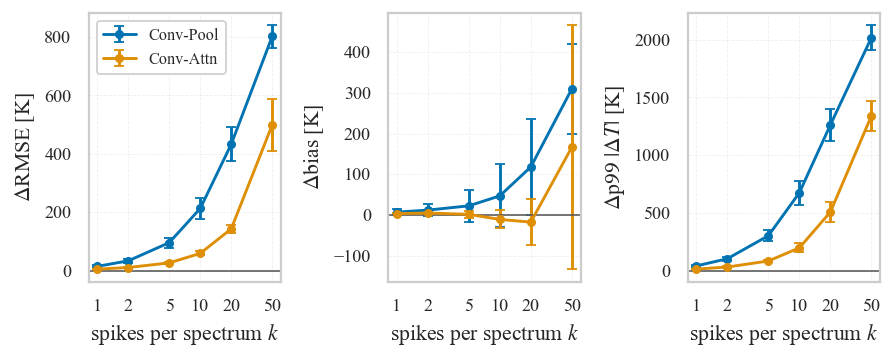

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(W_DOUBLE, 2.9))
panels = [('d_rmse_K', r'$\Delta$RMSE [K]'),
          ('d_bias_K', r'$\Delta$bias [K]'),
          ('d_p99_abs_K', r'$\Delta$p99 $|\Delta T|$ [K]')]

for ax, (col, ylab) in zip(axes, panels):
    for m in MODELS:
        g = ov_k[ov_k.model == m].groupby('k')[col]
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xscale('log')
    ax.set_xticks(K_LEVELS)
    ax.set_xticklabels(K_LEVELS)
    ax.set_xlabel('spikes per spectrum $k$')
    ax.set_ylabel(ylab)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

axes[0].legend(loc='upper left', framealpha=0.92, fontsize=9)
plt.tight_layout()
plt.show()

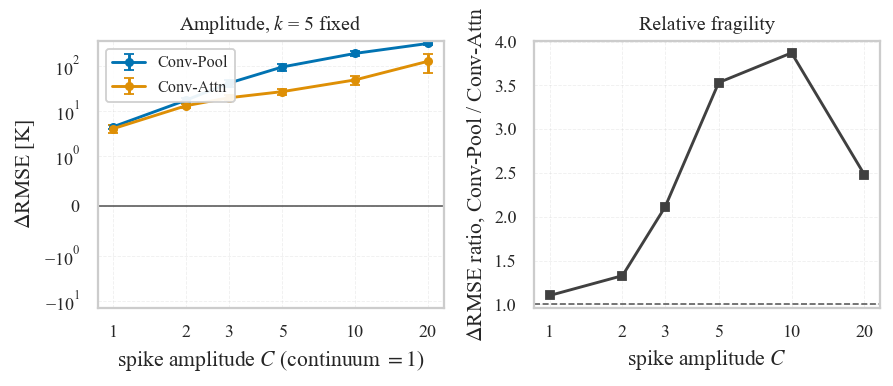

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.1))

for m in MODELS:
    g = ov_c[ov_c.model == m].groupby('C')['d_rmse_K']
    axes[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
axes[0].axhline(0, color='0.35', lw=0.9)
axes[0].set_xscale('log')
axes[0].set_yscale('symlog', linthresh=1)
axes[0].set_xticks(C_LEVELS)
axes[0].set_xticklabels([f'{c:g}' for c in C_LEVELS])
axes[0].set_xlabel('spike amplitude $C$ (continuum $= 1$)')
axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].set_title(f'Amplitude, $k$ = {K_REF} fixed', fontsize=11)
axes[0].legend(loc='upper left', framealpha=0.92, fontsize=9)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

axes[1].plot(pic.index, pic['ratio_Pool_over_Attn'], color='0.25',
             marker='s', ms=4, lw=1.6)
axes[1].axhline(1, color='0.35', lw=0.9, ls='--')
axes[1].set_xscale('log')
axes[1].set_xticks(C_LEVELS)
axes[1].set_xticklabels([f'{c:g}' for c in C_LEVELS])
axes[1].set_xlabel('spike amplitude $C$')
axes[1].set_ylabel(r'$\Delta$RMSE ratio, Conv-Pool / Conv-Attn')
axes[1].set_title('Relative fragility', fontsize=11)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

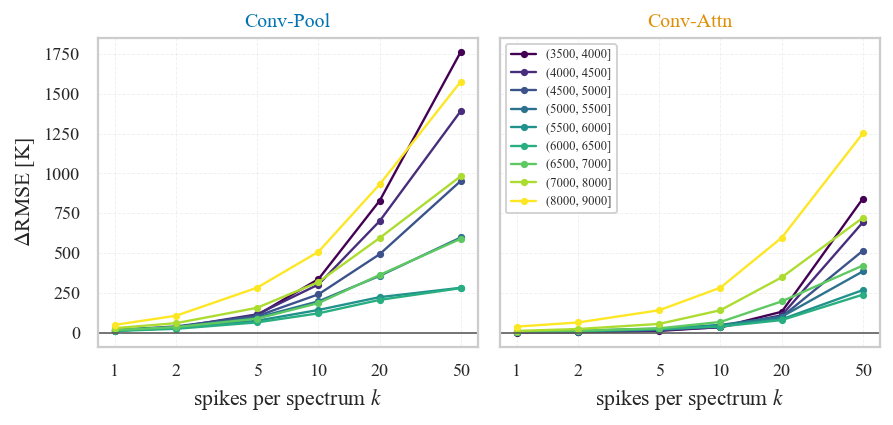

In [16]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(W_DOUBLE, 3.4), sharey=True)
cmap = plt.get_cmap('viridis')

for ax, m in zip(np.atleast_1d(axes), MODELS):
    sub = deg_k[(deg_k.model == m) & (deg_k.regime != 'all')]
    for i, lab in enumerate(REG_LABELS):
        g = sub[sub.regime == lab].groupby('k')['d_rmse_K'].mean()
        ax.plot(g.index, g.values, color=cmap(i / (len(REG_LABELS) - 1)),
                marker='o', ms=3, lw=1.3, label=lab)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xscale('log')
    ax.set_xticks(K_LEVELS)
    ax.set_xticklabels(K_LEVELS)
    ax.set_xlabel('spikes per spectrum $k$')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

np.atleast_1d(axes)[0].set_ylabel(r'$\Delta$RMSE [K]')
np.atleast_1d(axes)[-1].legend(fontsize=7, loc='upper left', framealpha=0.92)
plt.tight_layout()
plt.show()

## 5.1.9 Export

All dictionaries below are built with explicit loops rather than comprehensions containing `DataFrame.query`, and the exported summary is checked against the tables above before the notebook ends.

In [17]:
def level_summary(df, level_col, levels):
    out = {}
    for m in MODELS:
        per_level = {}
        for lv in levels:
            sub = df[(df[level_col] == lv) & (df['model'] == m)]['d_rmse_K']
            per_level[str(lv)] = [float(sub.mean()), float(sub.std())]
        out[m] = per_level
    return out


meta = {
    'step': '5.1',
    'attack': ATTACK,
    'description': 'flux replaced by a fixed value C at k random pixels per spectrum',
    'attack_seed': ATTACK_SEED,
    'positions': 'k distinct pixels per spectrum, uniform over the full grid',
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'eval_batch_size': BATCH_SIZE,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'sweep_density': {'k_levels': K_LEVELS, 'C_fixed': C_REF,
                      'n_repeats': N_REPEATS_K,
                      'd_rmse_K': level_summary(ov_k, 'k', K_LEVELS)},
    'sweep_amplitude': {'C_levels': C_LEVELS, 'k_fixed': K_REF,
                        'n_repeats': N_REPEATS_C,
                        'positions_shared_with_density_sweep': True,
                        'd_rmse_K': level_summary(ov_c, 'C', C_LEVELS)},
}
with open(os.path.join(RESULTS_DIR, 'step51_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

tests.to_csv(os.path.join(RESULTS_DIR, 'step51_paired_tests.csv'), index=False)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step51_')):
    print(f'  {fn:38s} {os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1024:7.1f} KB')
tot = sum(os.path.getsize(os.path.join(STEP51_DIR, f))
          for f in os.listdir(STEP51_DIR)) / 1024 ** 2
print(f'  step51/  (per-spectrum predictions and spike positions)  {tot:.1f} MB')

# sanity: the exported summary must agree with the table printed above
for m in MODELS:
    a = meta['sweep_density']['d_rmse_K'][m]['5'][0]
    b = float(ov_k[(ov_k.k == 5) & (ov_k.model == m)]['d_rmse_K'].mean())
    assert abs(a - b) < 1e-9, f'exported summary disagrees with the table for {m}'
print('\nExported summary verified against the in-notebook tables.')

Written to results/:
  step51_degradation_amplitude.csv         183.5 KB
  step51_degradation_density.csv           181.6 KB
  step51_meta.json                           3.1 KB
  step51_paired_tests.csv                    0.7 KB
  step51/  (per-spectrum predictions and spike positions)  17.3 MB

Exported summary verified against the in-notebook tables.


### Stored per-spectrum predictions

`results/step51/preds_k*.npz` holds, for every level of both sweeps, the prediction of every network on every spectrum together with the spike positions that produced it. Section 5.1.10 uses the $k = 1$ level of these files to map the damage a single spike does against the wavelength it lands on.

## 5.1.10 Where a spike does the most damage

This analysis costs nothing new: the $k = 1$ level already stored, for every spectrum, both the pixel that was corrupted and the prediction that resulted. Binning the per-spectrum damage by spike position gives a susceptibility profile across the band, which can be read against the diagnostic features. The profile is Fig. 2b of the paper, and the spread printed at the end gives the range of single-spike damage quoted in the text.

Clean per-spectrum predictions are needed for the difference. They are recomputed once here and cached, rather than parsed out of the Step 4 artefacts, so that this section does not depend on that file naming.

In [18]:
CLEAN_CACHE = os.path.join(STEP51_DIR, 'clean_predictions.npz')

if os.path.exists(CLEAN_CACHE):
    _z = np.load(CLEAN_CACHE)
    clean_preds = _z['preds']                     # (seeds, models, N_TEST)
    print(f'[skip] loaded {CLEAN_CACHE}')
else:
    clean_preds = np.empty((len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            clean_preds[si, mi] = predict(model, X_clean).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    np.savez_compressed(CLEAN_CACHE, preds=clean_preds,
                        seeds=np.array(SEEDS), models=np.array(MODELS))
    print(f'[saved] {CLEAN_CACHE}')

# cross-check against the aggregated baseline of Step 5.0
for si, seed in enumerate(SEEDS):
    for mi, m in enumerate(MODELS):
        r = float(np.sqrt(np.mean((clean_preds[si, mi] - y_true_k) ** 2)))
        ref = float(clean_metrics[(clean_metrics.model == m) &
                                  (clean_metrics.seed == seed) &
                                  (clean_metrics.regime == 'all')]['rmse_K'].iloc[0])
        assert abs(r - ref) < 0.05, f'clean predictions disagree with Step 5.0 for {m} seed {seed}'
print('Clean predictions verified against the Step 5.0 baseline.')

[saved] results\step51\clean_predictions.npz
Clean predictions verified against the Step 5.0 baseline.


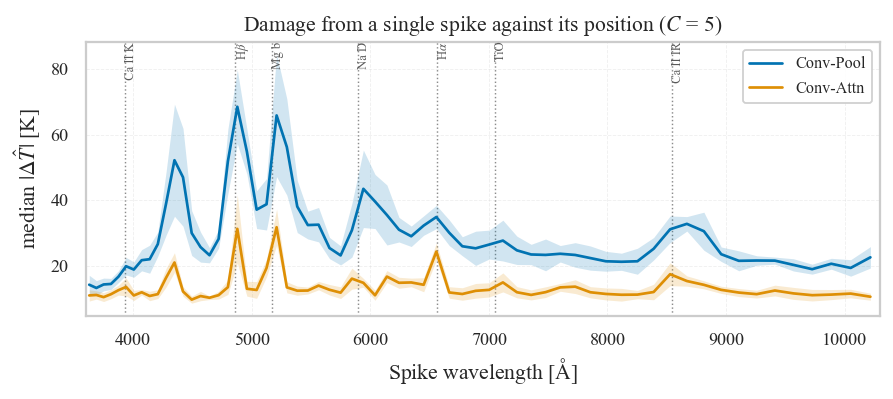

Spread of damage across the band:


,mean,std,min,max,max_over_min
model,,,,,
Conv-Attn,13.59,4.67,7.56,50.9,6.73
Conv-Pool,29.39,13.24,10.16,97.3,9.58


A ratio near 1 would mean position hardly matters, and the vulnerability is to the presence of an outlier rather than to the loss of any particular feature.


In [19]:
z1 = np.load(path_k(1))
pos1 = z1['positions']                 # (repeats, N_TEST, 1)
prd1 = z1['preds']                     # (repeats, seeds, models, N_TEST)

NBINS = 64
edges = np.linspace(0, GRID_N, NBINS + 1)
centres = 0.5 * (edges[:-1] + edges[1:])

sus_rows = []
for rep in range(prd1.shape[0]):
    p = pos1[rep, :, 0].astype(np.int64)
    b = np.clip(np.digitize(p, edges) - 1, 0, NBINS - 1)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            d = np.abs(prd1[rep, si, mi].astype(np.float64) - clean_preds[si, mi])
            for bi in range(NBINS):
                sel = b == bi
                if sel.sum() >= 20:
                    sus_rows.append({'repeat': rep, 'seed': seed, 'model': m,
                                     'bin': bi, 'pixel': centres[bi],
                                     'n': int(sel.sum()),
                                     'damage_median': float(np.median(d[sel]))})

sus = pd.DataFrame(sus_rows)
sus.to_csv(os.path.join(RESULTS_DIR, 'step51_susceptibility.csv'), index=False)

wave = prep['grid']['wave_start'] * (prep['grid']['wave_end'] / prep['grid']['wave_start']) \
       ** (np.arange(GRID_N) / (GRID_N - 1))
sus['lambda_A'] = np.interp(sus['pixel'], np.arange(GRID_N), wave)

LINES = {'Ca II K': 3933.7, r'H$\beta$': 4861.3, 'Mg b': 5175.0,
         'Na D': 5893.0, r'H$\alpha$': 6562.8, 'TiO': 7055.0, 'Ca II IR': 8542.1}

fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.2))
for m in MODELS:
    g = sus[sus.model == m].groupby('lambda_A')['damage_median']
    ax.plot(g.mean().index, g.mean().values, color=COLORS[m], lw=1.5, label=m)
    ax.fill_between(g.mean().index, g.mean() - g.std(), g.mean() + g.std(),
                    color=COLORS[m], alpha=0.18, lw=0)
ymax = ax.get_ylim()[1]
for name, lam in LINES.items():
    ax.axvline(lam, color='0.55', ls=':', lw=0.8, zorder=0)
    ax.text(lam, ymax, f' {name}', rotation=90, va='top', ha='left',
            fontsize=7, color='0.35')
ax.set_xlabel(r'Spike wavelength [$\mathrm{\AA}$]')
ax.set_ylabel(r'median $|\Delta \hat{T}|$ [K]')
ax.set_title(f'Damage from a single spike against its position ($C$ = {C_REF:g})',
             fontsize=12)
ax.set_xlim(wave[0], wave[-1])
ax.legend(loc='upper right', framealpha=0.92, fontsize=9)
ax.grid(True, ls='--', alpha=0.3, lw=0.5)
plt.tight_layout()
plt.show()

flat = sus.groupby(['model'])['damage_median'].agg(['mean', 'std', 'min', 'max'])
flat['max_over_min'] = flat['max'] / flat['min']
print('Spread of damage across the band:')
display(flat.round(2))
print('A ratio near 1 would mean position hardly matters, and the vulnerability is to '
      'the presence of an outlier rather than to the loss of any particular feature.')